# 07 · Ablation study of the dual-scale GNO (four input fields)

Each variant changes one part of ours (w16, 8×16 modes, GNO readout 60 / 10 km, MLP head starting at
the four-model mean, four input fields) and is trained with the same five spatial folds; every
score is on the held-out stations, on the same samples as in notebook 06 (with a MET Nordic analysis).

| Variant | Change |
|---|---|
| no global branch | `--branches regional`: only MEPS + AROME-Arctic are encoded |
| no regional branch | `--branches global`: only IFS + AIFS are encoded |
| bilinear readout | `--readout bilinear`: the GNOs are replaced by bilinear sampling of the latent fields |
| linear head | single linear output projection instead of the MLP head |
| no zero start | MLP head with random initialisation (training does not start at the four-model mean) |
| no terrain | `--no-terrain`: the 28 terrain point features T(x) are dropped |

RMSE: mean of the seeds' RMSE. Uncertainty: s.d. over the seeds, and a bootstrap over the test runs
(1000 draws, whole runs resampled). ΔRMSE against ours uses a *paired* bootstrap: the same runs are
drawn for the variant and for ours, so the common sample noise cancels.

Original period: train 2024-03 – 2024-12, test 2025-04-01 – 2025-09-12.

In [1]:
import sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
sys.path.insert(0, '../scripts/report_unified_inputs')
import duallib as D
from station_results import metnordic_at_stations

ORANGE, INK, INK2 = '#eb6834', '#0b0b0b', '#52514e'
MM = 1 / 25.4
FIG = Path('figs/07'); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    'figure.dpi': 220, 'savefig.dpi': 600, 'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'font.family': 'sans-serif', 'font.sans-serif': ['Arial', 'Liberation Sans', 'DejaVu Sans'],
    'font.size': 7, 'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5,
    'axes.linewidth': .6, 'xtick.major.width': .6, 'ytick.major.width': .6, 'xtick.major.size': 2.5,
    'ytick.major.size': 2.5, 'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
    'lines.linewidth': 1.2, 'pdf.fonttype': 42, 'svg.fonttype': 'none'})

def save(fig, name):
    fig.savefig(FIG / f'{name}.pdf', bbox_inches='tight')
    fig.savefig(FIG / f'{name}.png', bbox_inches='tight')

OURS = f'rg60_rr10_{D.SMALL}_head-mlp'            # dual-scale GNO, four fields

P = D.Period('original')
mn = metnordic_at_stations(P)
P.mask &= np.isfinite(mn).all(-1)                   # same samples as notebook 06
runs = np.where(P.mask.any((1, 2)))[0]
NB = 1000
idx = np.random.default_rng(1).integers(0, len(runs), (NB, len(runs)))
LEADS = P.leads
print(f'{P.mask.sum():,} samples, {len(runs)} test runs, {P.mask.any((0, 1)).sum()} stations')

def run_sums(f):
    # per test run: sum of squared vector errors and number of samples
    e = np.where(P.mask, np.sum((f - P.obs) ** 2, -1), 0.0)
    return e.sum((1, 2)), P.mask.sum((1, 2))

def seed_rmse(fs):
    # point RMSE, bootstrap draws (NB,) and seed s.d.; RMSE = mean over the seeds' RMSE
    sums = [run_sums(f) for f in fs]
    r = [np.sqrt(se[runs].sum() / n[runs].sum()) for se, n in sums]
    boot = np.mean([np.sqrt(se[runs][idx].sum(1) / n[runs][idx].sum(1)) for se, n in sums], 0)
    return np.mean(r), boot, (np.std(r) if len(fs) > 1 else np.nan)


367,427 samples, 328 test runs, 98 stations


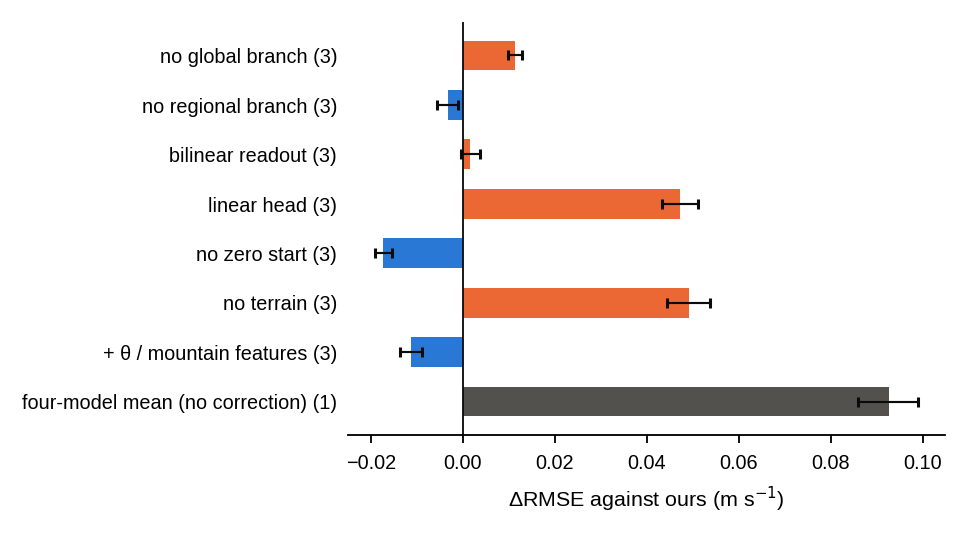

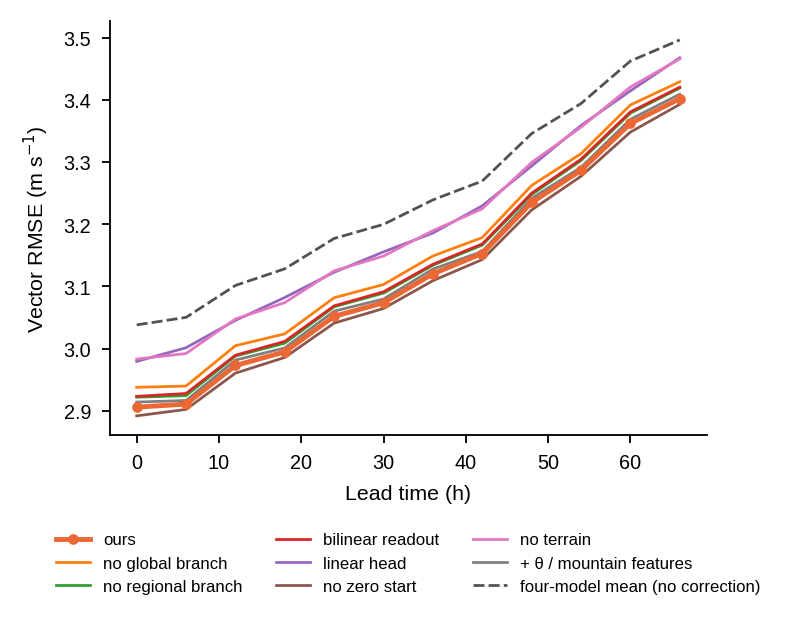

\begin{tabular}{lccc}
\toprule
Variant & Seeds & RMSE (m\,s$^{-1}$) & $\Delta$RMSE vs WindCast \\
\midrule
\textbf{WindCast} & 3 & $3.153 \pm 0.029$ & -- \\
no global branch & 3 & $3.164 \pm 0.029$ & $+0.011 \pm 0.001$ \\
no regional branch & 3 & $3.149 \pm 0.029$ & $-0.003 \pm 0.001$ \\
bilinear readout & 3 & $3.154 \pm 0.029$ & $+0.002 \pm 0.001$ \\
linear head & 3 & $3.200 \pm 0.030$ & $+0.047 \pm 0.002$ \\
no zero start & 3 & $3.135 \pm 0.029$ & $-0.017 \pm 0.001$ \\
no terrain & 3 & $3.202 \pm 0.031$ & $+0.049 \pm 0.002$ \\
+ $\theta$ / mountain features & 3 & $3.142 \pm 0.029$ & $-0.011 \pm 0.001$ \\
four-model mean (no correction) & 1 & $3.245 \pm 0.031$ & $+0.093 \pm 0.003$ \\
\bottomrule
\end{tabular}


,seeds,RMSE,seed s.d.,bootstrap s.d.,ΔRMSE vs ours,Δ s.d. (paired),Δ 95% low,Δ 95% high
variant,,,,,,,,
ours,3,3.153,0.007,0.029,0.000,0.000,0.000,0.000
no global branch,3,3.164,0.001,0.029,0.011,0.001,0.010,0.013
no regional branch,3,3.149,0.003,0.029,-0.003,0.001,-0.006,-0.001
bilinear readout,3,3.154,0.008,0.029,0.002,0.001,-0.000,0.004
linear head,3,3.200,0.001,0.030,0.047,0.002,0.043,0.051
no zero start,3,3.135,0.009,0.029,-0.017,0.001,-0.019,-0.016
no terrain,3,3.202,0.002,0.031,0.049,0.002,0.044,0.054
+ θ / mountain features,3,3.142,0.001,0.029,-0.011,0.001,-0.014,-0.009
four-model mean (no correction),1,3.245,NaN,0.031,0.093,0.003,0.086,0.099


In [2]:
ABL = [  # label, run tag (None: the four-model mean, no training)
    ('ours', OURS),
    ('no global branch', f'regional_rr10_{D.SMALL}_head-mlp'),
    ('no regional branch', f'global_rg60_{D.SMALL}_head-mlp'),
    ('bilinear readout', f'bilinear_{D.SMALL}_head-mlp'),
    ('linear head', f'rg60_rr10_{D.SMALL}'),
    ('no zero start', 'rg60_rr10_r16m8x16_g16m8x16_head-mlp'),
    ('no terrain', f'rg60_rr10_{D.SMALL}_head-mlp_noterr'),
    ('+ θ / mountain features', f'rg60_rr10_phys-all_{D.SMALL}_head-mlp'),
    ('four-model mean (no correction)', None)]

ABLF, rows = {}, []
for lab, tag in ABL:
    fs = [P.base['mix']] if tag is None else list(P.seeds(P.dual, tag).values())
    if not fs:
        print(f'{lab}: no complete seed yet'); continue
    ABLF[lab] = fs
    rows.append((lab, len(fs)) + seed_rmse(fs))
ref_point, ref_boot = rows[0][2], rows[0][3]
abl = pd.DataFrame([{
    'variant': lab, 'seeds': n, 'RMSE': p, 'seed s.d.': sd, 'bootstrap s.d.': b.std(),
    'ΔRMSE vs ours': p - ref_point, 'Δ s.d. (paired)': (b - ref_boot).std(),
    'Δ 95% low': np.percentile(b - ref_boot, 2.5), 'Δ 95% high': np.percentile(b - ref_boot, 97.5)}
    for lab, n, p, b, sd in rows]).set_index('variant')
abl.round(3).to_csv(FIG / 'ablation.csv')

# LaTeX table for the report
lines = [r'\begin{tabular}{lccc}', r'\toprule',
         r'Variant & Seeds & RMSE (m\,s$^{-1}$) & $\Delta$RMSE vs WindCast \\', r'\midrule']
for lab, r in abl.iterrows():
    name = r'\textbf{WindCast}' if lab == 'ours' else lab.replace('θ', r'$\theta$')
    d = '--' if lab == 'ours' else f"${r['ΔRMSE vs ours']:+.3f} \\pm {r['Δ s.d. (paired)']:.3f}$"
    lines.append(f"{name} & {int(r['seeds'])} & ${r['RMSE']:.3f} \\pm {r['bootstrap s.d.']:.3f}$ & {d} \\\\")
lines += [r'\bottomrule', r'\end{tabular}']
(FIG / 'table_ablation.tex').write_text('\n'.join(lines) + '\n')

# Fig. 6: ΔRMSE against ours with the paired 95 % interval
a = abl.drop('ours')
fig, ax = plt.subplots(figsize=(89 * MM, 62 * MM))
y = np.arange(len(a))[::-1]
col = [INK2 if lab.startswith('four') else ('#2a78d6' if d < 0 else ORANGE) for lab, d in a['ΔRMSE vs ours'].items()]
ax.barh(y, a['ΔRMSE vs ours'], color=col, height=.6)
ax.errorbar(a['ΔRMSE vs ours'], y, xerr=[a['ΔRMSE vs ours'] - a['Δ 95% low'], a['Δ 95% high'] - a['ΔRMSE vs ours']],
            fmt='none', ecolor=INK, elinewidth=.7, capsize=1.5)
ax.axvline(0, color=INK, lw=.6)
ax.set_yticks(y, [f'{lab} ({n})' for lab, n in a['seeds'].items()])
ax.set_xlabel('ΔRMSE against ours (m s$^{-1}$)')
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
save(fig, 'fig1_ablation')
plt.show()

# Fig. 7: RMSE by lead time per variant (seed-mean forecast)
fig, ax = plt.subplots(figsize=(89 * MM, 62 * MM))
cols = plt.cm.tab10(np.linspace(0, 1, 10))
for i, (lab, fs) in enumerate(ABLF.items()):
    kw = dict(color=ORANGE, lw=1.6, marker='o', ms=2.5, zorder=5) if lab == 'ours' else dict(color=cols[i % 10], lw=.9)
    if lab.startswith('four'):
        kw = dict(color=INK2, lw=.9, ls=(0, (4, 1.5)))
    ax.plot(LEADS, P.rmse_lead(np.mean(fs, 0)), label=lab, **kw)
ax.set_xlabel('Lead time (h)'); ax.set_ylabel('Vector RMSE (m s$^{-1}$)')
ax.legend(fontsize=5.5, ncol=3, loc='upper center', bbox_to_anchor=(.5, -.2))
save(fig, 'fig2_ablation_lead')
plt.show()
print('\n'.join(lines))
abl.round(3)

**Fig. 1 | Ablation, original test period.** RMSE change of each variant against ours (positive:
worse), all lead times; bar colour orange = worse, blue = better, grey = no correction at all. Error
bars: 95 % interval of the paired bootstrap over the test runs (sample uncertainty only; the s.d. over
training seeds, 0.001–0.009 m/s, is in the table). In brackets: the number of seeds.
**Fig. 2** shows the same variants by lead time.